In [ ]:
#Install the packages required
!pip  install numpy pandas matplotlib seaborn scikit-learn tensorflow bnlearn scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 22.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.2/185.2 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 51.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.2 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659682 sha256=67e62d39126302e2d537c789246795066453a32e1e9fe8dbb9eb77c214b9eb3e
  Stored in directory: /root/.cache/pip/wheels/44/73/aa/17ef39e69a62fdb1cbda5d9ebf8318f130b12107bf05cad7f0
Successfully built semopy


In [ ]:

# Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import bnlearn as bn
from scipy.stats import pearsonr

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [ ]:
#Load the dataset
df = pd.read_excel('Subsistence Retail Consumer Data.xlsx')
print('Dataset Shape',df.shape)
df.head()

Dataset Shape (281, 41)


,Gender,Age,Marital Status,Employment Status,Level of Education,Regular Customer,Shopping frequency,E1,E2,E3,...,CT5,CT6,CT7,PV1,PV2,PV3,PI1,PI2,PI3,PI4
0,3,4,1,1,4,2,3,3,2,4,...,3,2,4,2,4,4,3,4,4,4
1,3,5,3,1,4,1,1,3,3,3,...,2,4,3,2,3,2,4,4,4,4
2,2,4,2,2,2,2,2,3,4,2,...,2,4,1,2,3,1,3,3,4,3
3,1,3,1,1,3,2,1,3,2,4,...,2,3,4,1,2,3,3,4,3,4
4,3,2,1,2,2,2,3,2,4,3,...,2,4,2,2,4,2,2,3,2,3


# Question 1

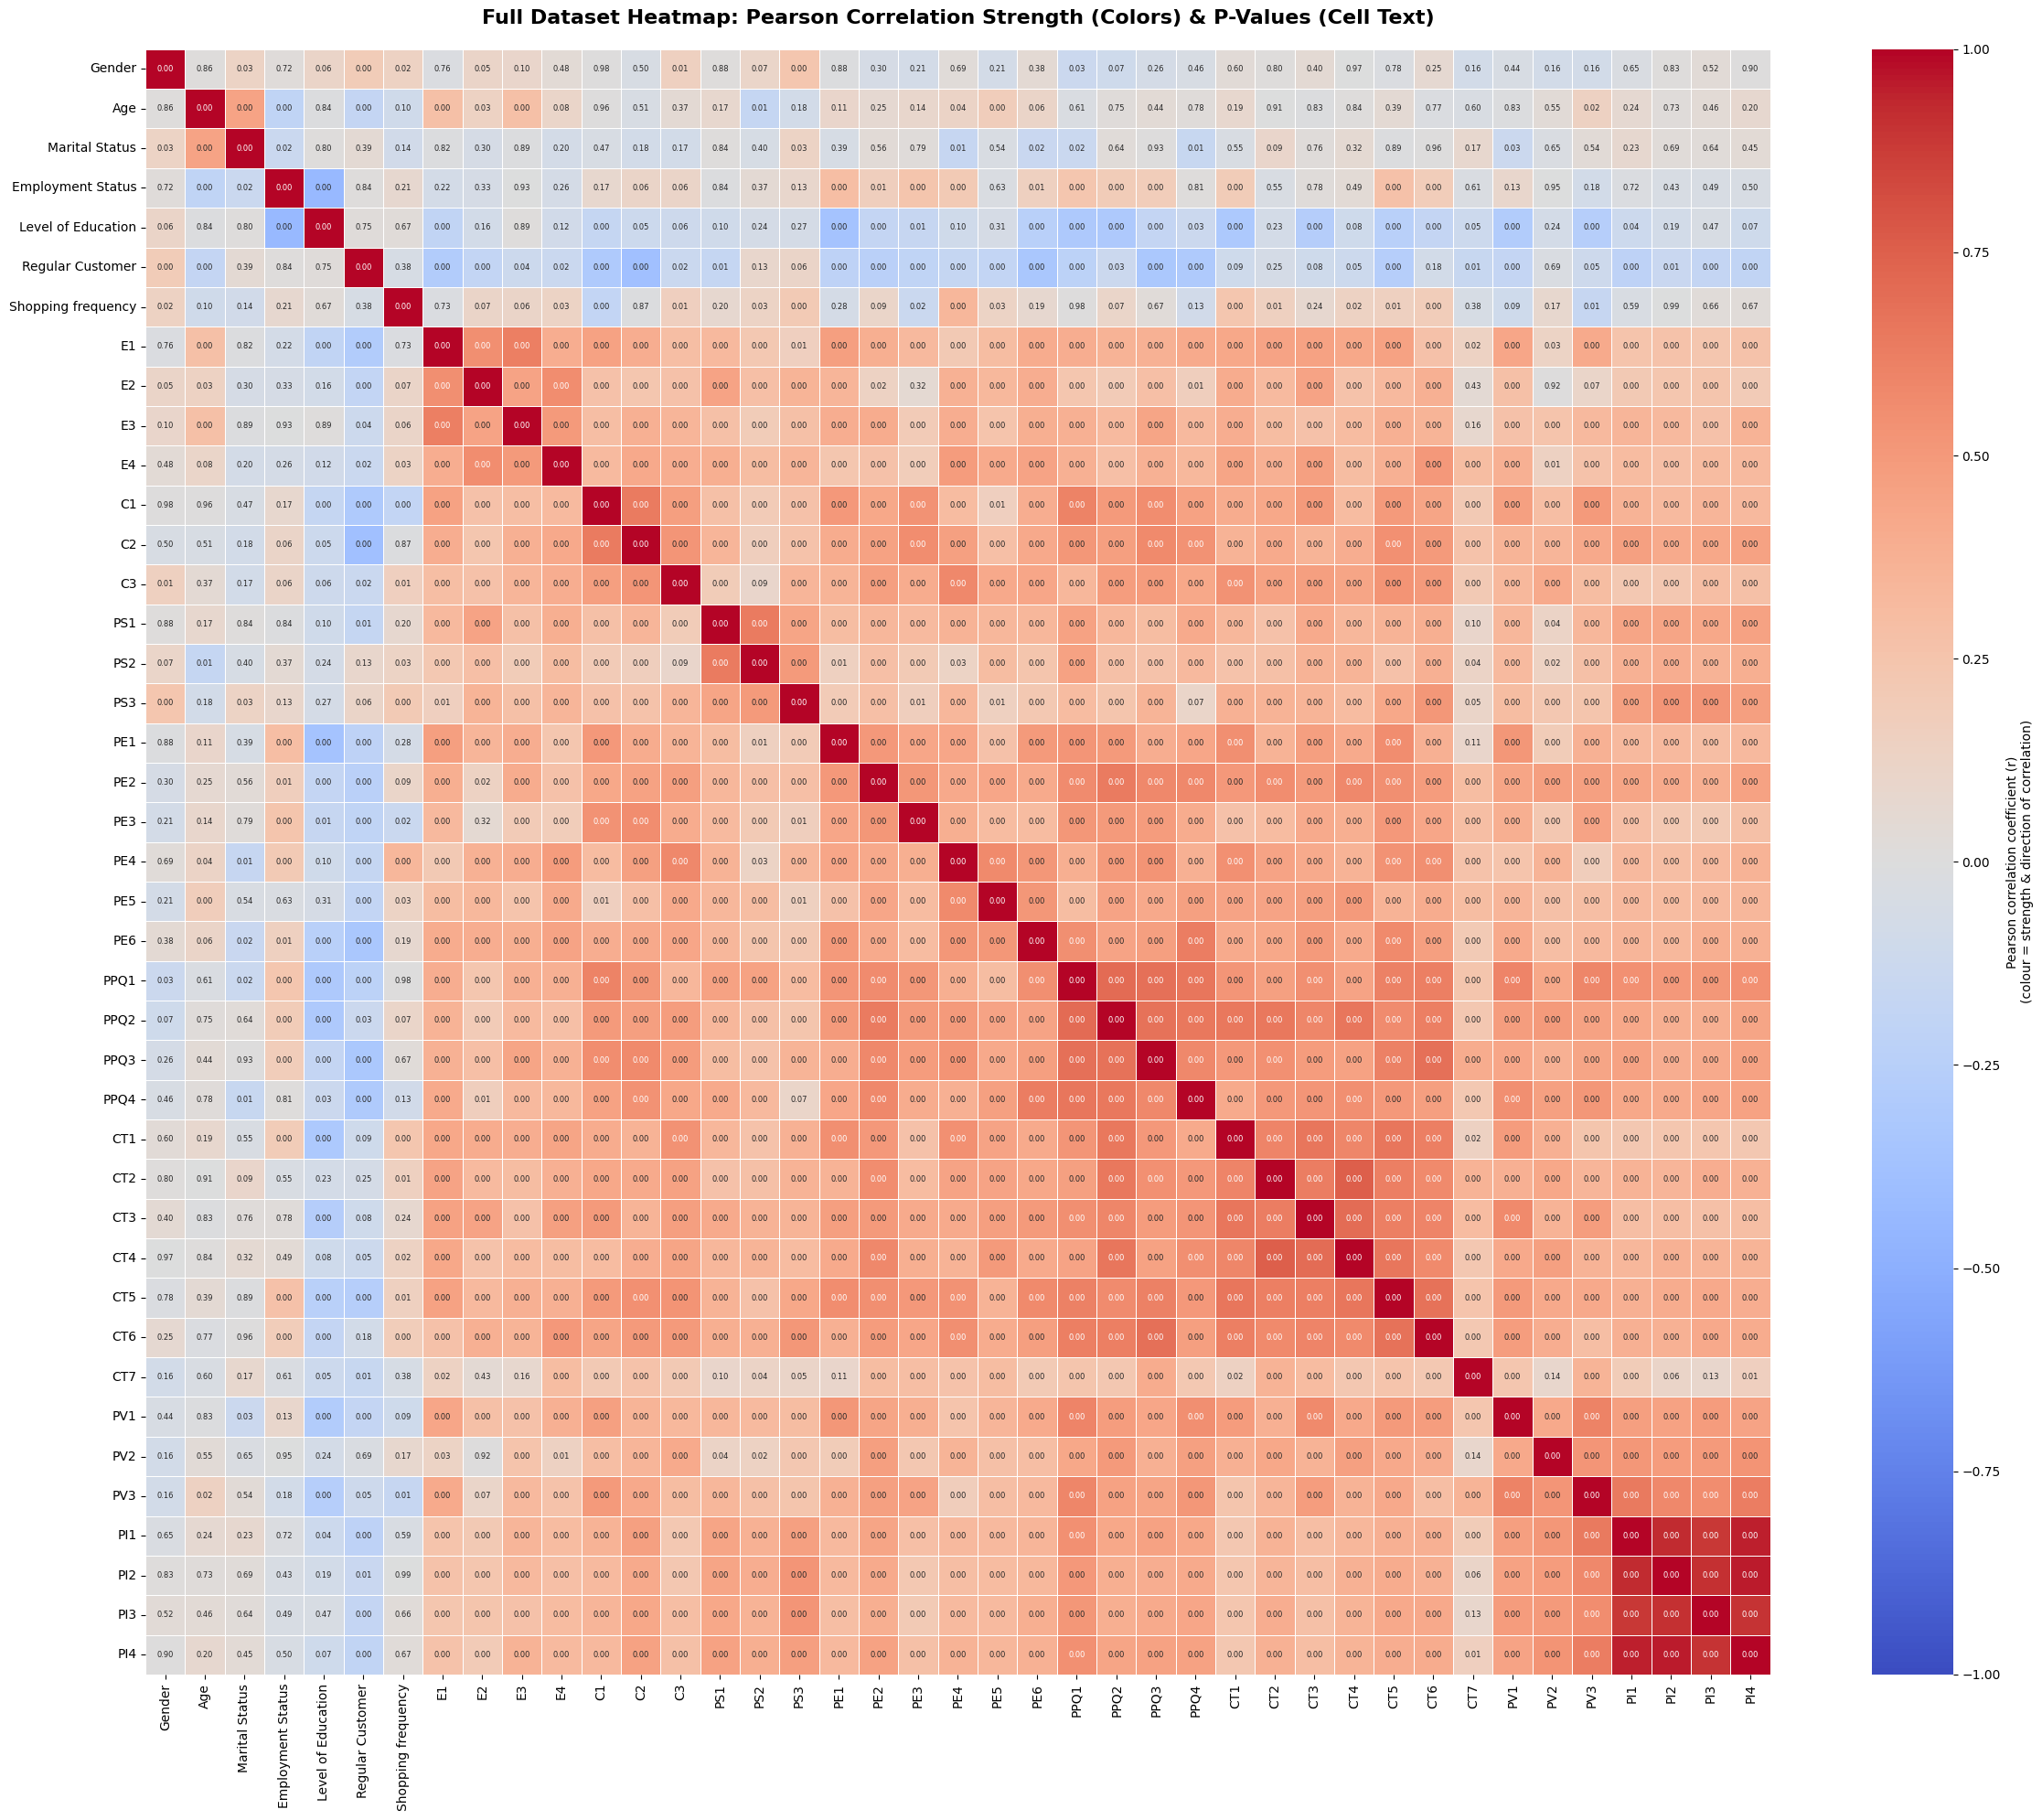

In [ ]:
#Question 1.1
#Convert all columns to numeric and drop incomplete rows
df_numeric = df.apply(pd.to_numeric, errors='coerce').dropna()

#Compute Full Pearson Correlation (r) and P-Value Matrices across ALL variables
cols = df_numeric.columns.tolist()
corr_full = pd.DataFrame(index=cols, columns=cols, dtype=float)
p_full = pd.DataFrame(index=cols, columns=cols, dtype=float)

for c1 in cols:
    for c2 in cols:
        r, p = pearsonr(df_numeric[c1], df_numeric[c2])
        corr_full.loc[c1, c2] = r
        p_full.loc[c1, c2] = p

#Plot Heatmap for the Full Dataset
plt.figure(figsize=(24, 20))

#Custom annotation formatting: display P-values rounded to 2 decimal places
annot_pvalues = p_full.astype(float).round(2).astype(str)

sns.heatmap(
    corr_full.astype(float),
    annot=p_full.astype(float),  # Display P-values inside cells
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation coefficient (r)\n(colour = strength & direction of correlation)"}, # Color scale legend
    annot_kws={"size": 6}
)

plt.title("Full Dataset Heatmap: Pearson Correlation Strength (Colors) & P-Values (Cell Text)", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

1.2 Understanding the Dataset

1. Regular Customer
2. Empathy: E3
3. Convinience: C2
4. Prise Sensitivity: PS3
5. Physical Environment: PE2
6. Perceived Product Quality: PPQ1
7. Customer Trust: CT5
8. Perceived Value: PV3
9. Purchase Intention: PI1


1.3 Justification of Variable Selection

(i) Why these specific variables?

Using the heatmap in Section 1.2 as the selection criterion, the chosen item in every category is the one that is most strongly and significantly correlated with the customer's overall purchase intention (PI_avg):

- Regular Customer(Demographics): This was the only demographic variable with a statistically significant relationship with purchase intention (r ≈ ‑0.19, p ≈ 0.0015). Gender, Age, Marital Status, Employment Status, Education and Shopping frequency did not reach statistical significance.This is an important EDA finding, as it suggests that purchase intention in this sample is not strongly influenced by traditional demographic characteristics, but rather by customer loyalty status.
- E3: Among the four empathy variables (E1–E4), E3 demonstrated the strongest correlation with purchase intention (r ≈ 0.33).
- C2: C2 was selected as the strongest convenience variable, with a correlation of approximately 0.45 with purchase intention.
- PS3: PS3 showed the strongest relationship among the price-sensitivity variables (r ≈ 0.51). This is one of the largest correlations in the dataset and supports the source paper's observation that customers within this segment are particularly sensitive to price.
- PE2: PE2 had the strongest correlation among the six physical-environment variables, with a correlation of approximately 0.44.
- PPQ1: PPQ1 was the strongest product-quality predictor (r ≈ 0.54). It represents the strongest predictor of purchase intention outside the PI variables themselves. Furthermore, PPQ1 has the highest factor loading within its construct in the original validated instrument, providing additional support for its selection.
- CT5: CT5 demonstrated the strongest relationship among the seven customer-trust variables, with a correlation of approximately 0.41.
- PV3: PV3 had the strongest correlation with purchase intention in the entire dataset outside the PI variables (r ≈ 0.62). This supports the findings of the original study, which identified perceived value as an important factor influencing purchasing behaviour within this market.
- PI1: PI1 was selected to represent the Purchase Intention construct and serve as the target variable for the Bayesian Network (BN). It is the first item in the validated PI scale and has an almost perfect correlation with the PI composite (r ≈ 0.97).

(ii) What insights do we expect?

Based on the correlation results, PV3 (perceived value) and PPQ1 (product quality) are expected to be the most influential variables in the Bayesian Network. The BN is therefore expected to support the source paper's finding that perceived value mediates the relationship between product quality and purchase intention. In other words, product quality may influence purchase intention primarily by shaping customers' perceptions of the value they receive, rather than having a strong direct effect on intention.

PS3 (price sensitivity) and CT5 (customer trust) are also expected to emerge as important secondary influences. This is particularly relevant within a bottom-of-the-pyramid township market, where affordability can strongly affect purchasing decisions and trust may play an important role when customers interact with informal or independent retailers.

The fact that none of the fixed demographic variables, apart from Regular Customer, met the significance criterion is also noteworthy. Once Regular Customer, which reflects behavioural loyalty rather than a fixed demographic characteristic, is incorporated into the network, the remaining demographic variables are expected to provide limited discriminatory value. Overall, the BN is therefore expected to place greater importance on customer loyalty, perceived value, product quality, price sensitivity, and trust than on traditional demographic characteristics.

#Question 2

[bnlearn]> Auto generate placeholders for the CPTs.
[bnlearn] >CPT for CT5:
+------------------+-----+---------------------+
| Regular Customer | ... | Regular Customer(1) |
+------------------+-----+---------------------+
| E3               | ... | E3(1)               |
+------------------+-----+---------------------+
| CT5(0)           | ... | 0.5                 |
+------------------+-----+---------------------+
| CT5(1)           | ... | 0.5                 |
+------------------+-----+---------------------+
[bnlearn] >CPT for PV3:
+--------+---------+---------+-----+---------+---------+---------+
| C2     | C2(0)   | C2(0)   | ... | C2(1)   | C2(1)   | C2(1)   |
+--------+---------+---------+-----+---------+---------+---------+
| PE2    | PE2(0)  | PE2(0)  | ... | PE2(1)  | PE2(1)  | PE2(1)  |
+--------+---------+---------+-----+---------+---------+---------+
| PPQ1   | PPQ1(0) | PPQ1(0) | ... | PPQ1(1) | PPQ1(1) | PPQ1(1) |
+--------+---------+---------+-----+---------+---------+-

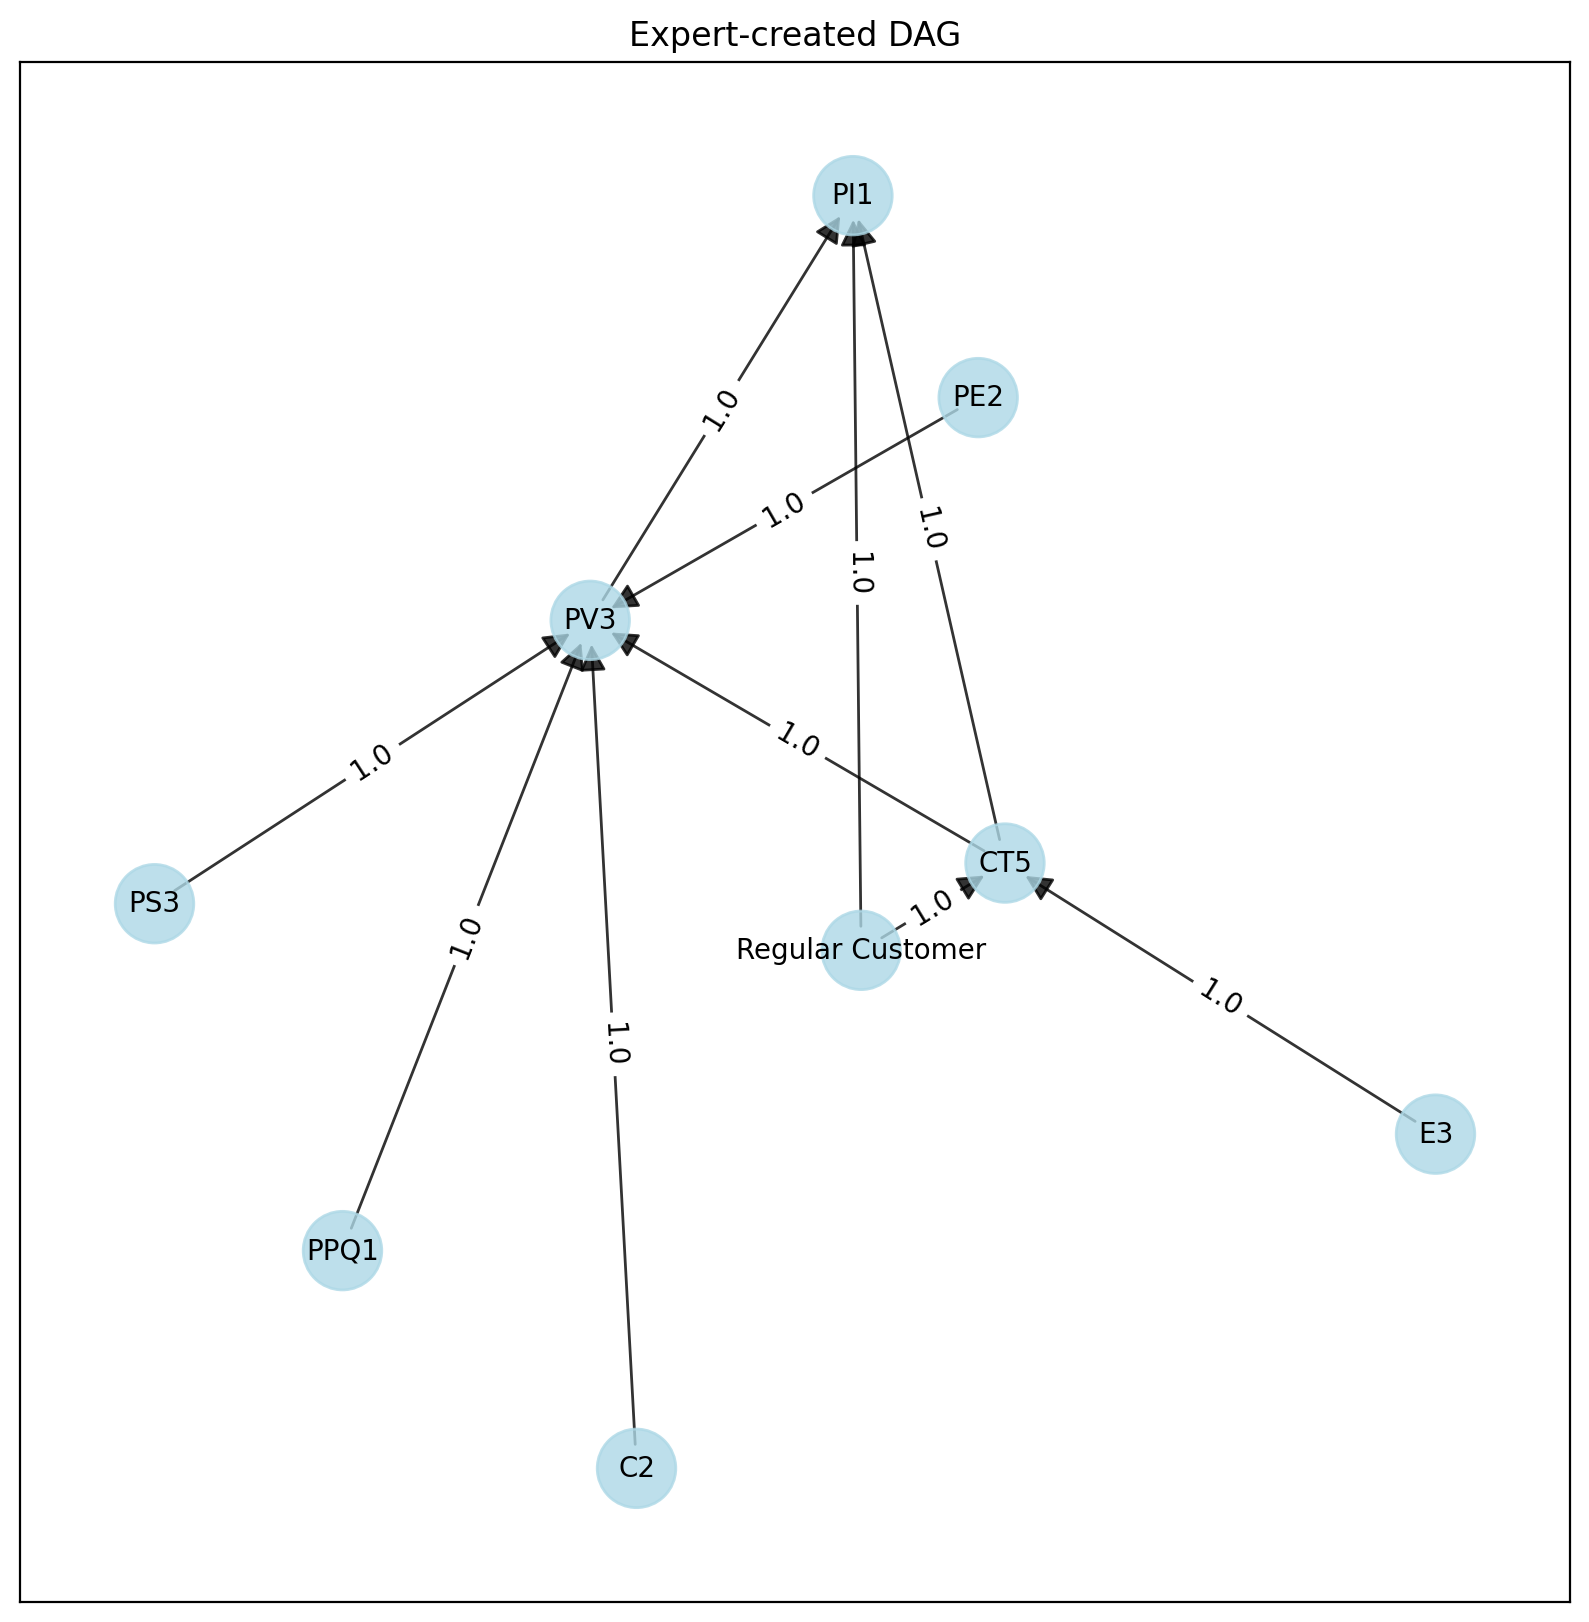

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'Regular Customer': array([ 0.14742274, -0.10059568]),
  'CT5': array([0.36091459, 0.00212661]),
  'E3': array([ 1.        , -0.31701327]),
  'C2': array([-0.18601475, -0.71045025]),
  'PV3': array([-0.25475713,  0.28787965]),
  'PE2': array([0.32116975, 0.55007397]),
  'PPQ1': array([-0.62246338, -0.45413108]),
  'PS3': array([-0.90150812, -0.04573318]),
  'PI1': array([0.13523629, 0.78784323])},
 'G': <networkx.classes.digraph.DiGraph at 0x787b670130e0>,
 'node_properties': {'Regular Customer': {'node_color': '#ADD8E6',
   'node_size': 800},
  'CT5': {'node_color': '#ADD8E6', 'node_size': 800},
  'E3': {'node_color': '#ADD8E6', 'node_size': 800},
  'C2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PV3': {'node_color': '#ADD8E6', 'node_size': 800},
  'PE2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PPQ1': {'node_color': '#ADD8E6', 'node_size': 800},
  'PS3': {'node_color': '#ADD

In [ ]:
#Question 2.1
edges_expert = [
    ('Regular Customer', 'CT5'),
    ('E3', 'CT5'),
    ('C2', 'PV3'),
    ('PE2', 'PV3'),
    ('PPQ1', 'PV3'),
    ('PS3', 'PV3'),
    ('CT5', 'PV3'),
    ('PV3', 'PI1'),
    ('CT5', 'PI1'),
    ('Regular Customer', 'PI1'),
]

DAG_expert = bn.make_DAG(edges_expert)
bn.plot(DAG_expert, title='Expert-created DAG')

[bnlearn] >Computing best DAG using [hc]
[bnlearn] >Set scoring type at [bic]
[bnlearn] >Compute structure scores for model comparison (higher is better).
[bnlearn] >Set node properties.
[bnlearn] >Set edge properties.
[bnlearn] >Plot based on Bayesian model


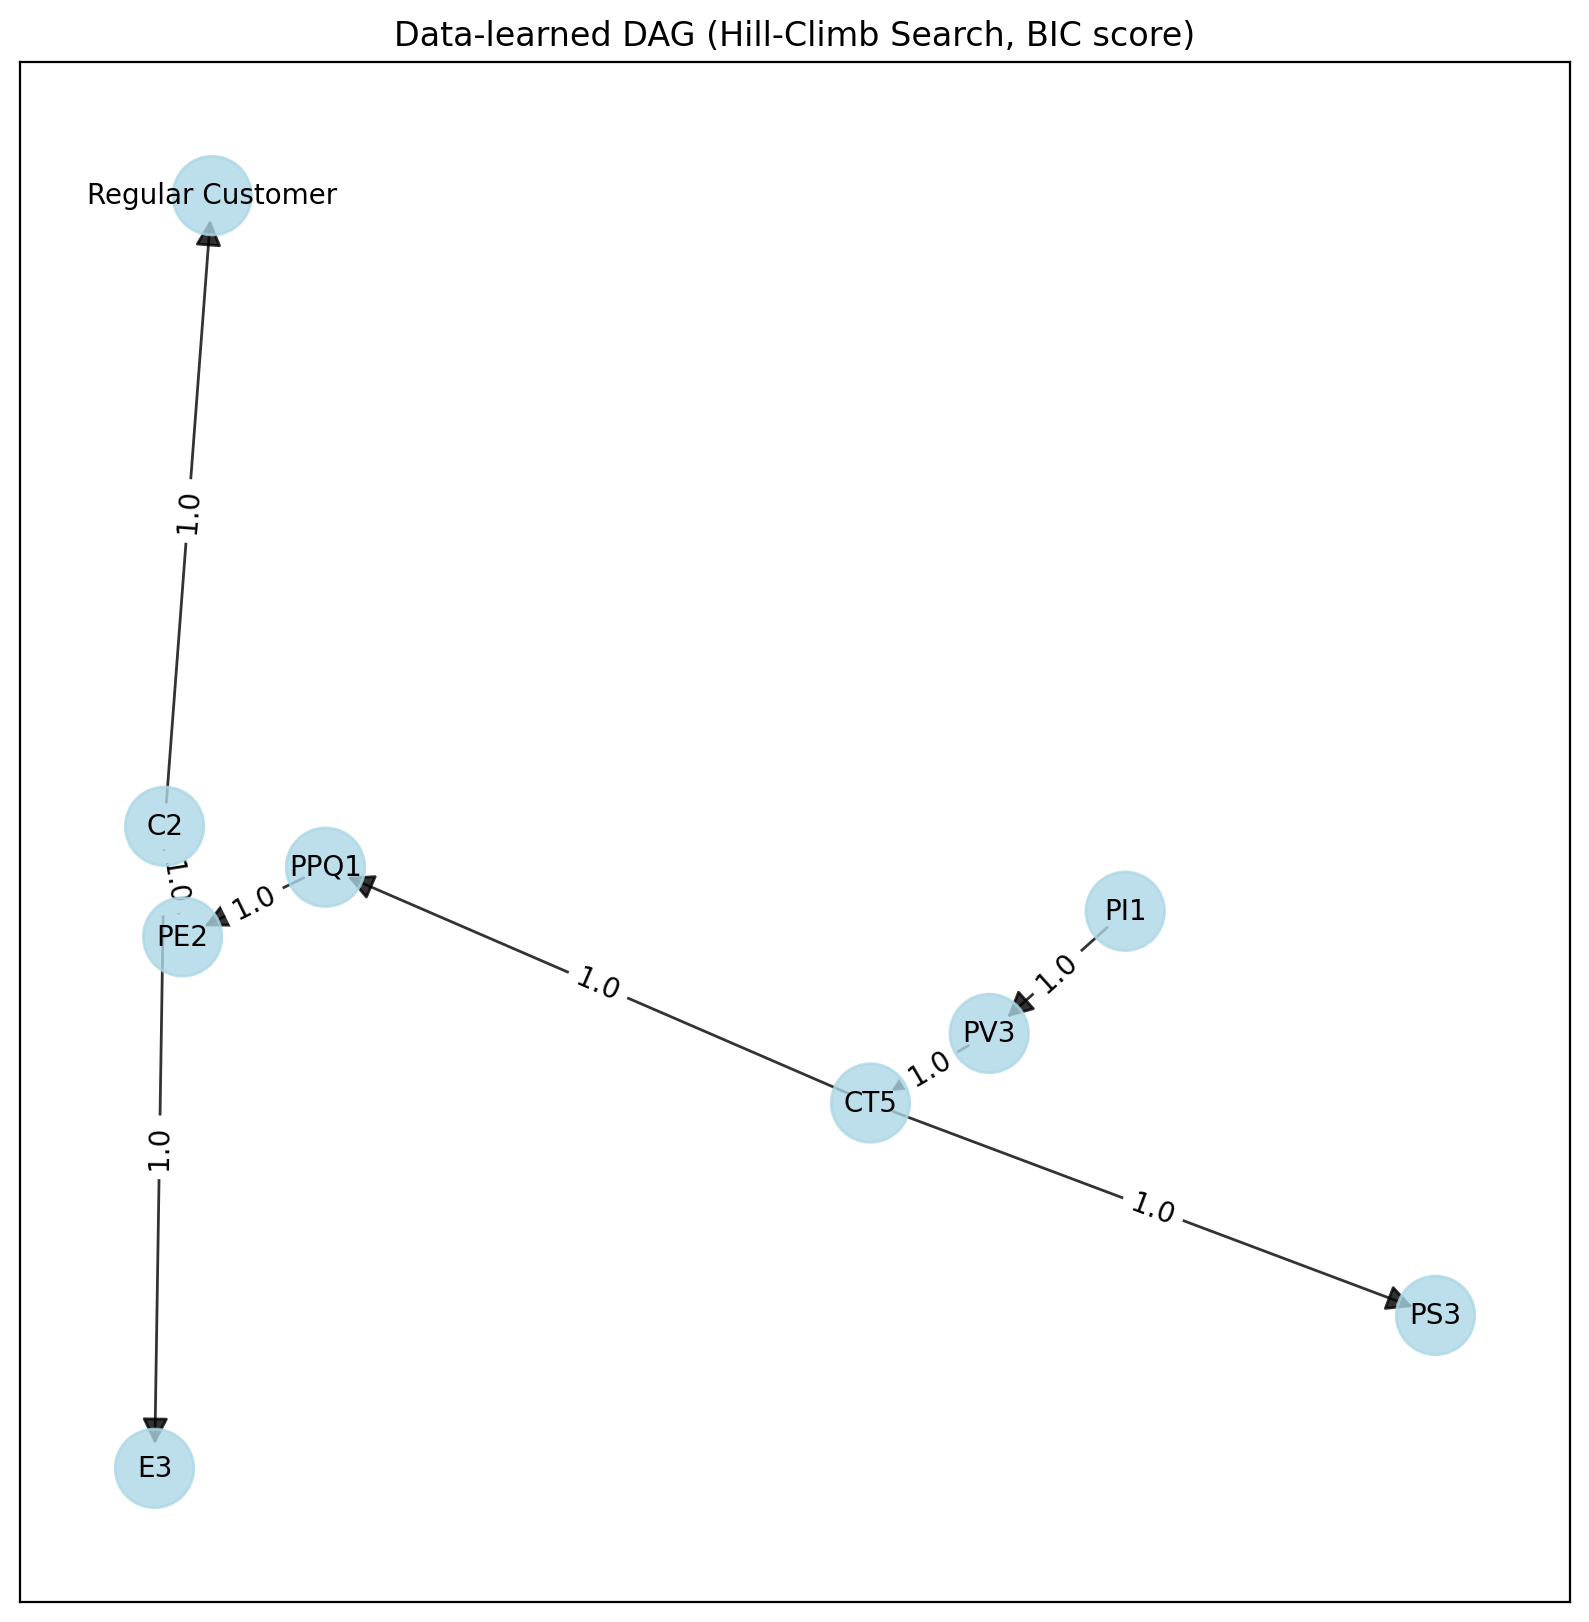

{'fig': <Figure size 2000x2000 with 1 Axes>,
 'ax': <Figure size 2000x2000 with 1 Axes>,
 'pos': {'Regular Customer': array([-0.33234484,  1.        ]),
  'E3': array([-0.38088952, -0.66084758]),
  'C2': array([-0.37239631,  0.1770038 ]),
  'PS3': array([ 0.6982651 , -0.46122873]),
  'PE2': array([-0.35725329,  0.03271239]),
  'PPQ1': array([-0.23685332,  0.12362074]),
  'CT5': array([ 0.22225175, -0.18412367]),
  'PV3': array([ 0.32230762, -0.09327492]),
  'PI1': array([0.4369128 , 0.06613796])},
 'G': <networkx.classes.digraph.DiGraph at 0x787b62eb6f10>,
 'node_properties': {'Regular Customer': {'node_color': '#ADD8E6',
   'node_size': 800},
  'E3': {'node_color': '#ADD8E6', 'node_size': 800},
  'C2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PS3': {'node_color': '#ADD8E6', 'node_size': 800},
  'PE2': {'node_color': '#ADD8E6', 'node_size': 800},
  'PPQ1': {'node_color': '#ADD8E6', 'node_size': 800},
  'CT5': {'node_color': '#ADD8E6', 'node_size': 800},
  'PV3': {'node_color': '

In [ ]:
#Question 2.2

selected_vars = ['Regular Customer', 'E3', 'C2', 'PS3', 'PE2', 'PPQ1', 'CT5', 'PV3', 'PI1']
df_bn = df[selected_vars].copy()

#Learn structure using Hill-Climb Search with BIC score criterion
model_learned = bn.structure_learning.fit(df_bn,
                                     methodtype='hc',
                                     scoretype='bic'
                                     )
bn.plot(model_learned, title='Data-learned DAG (Hill-Climb Search, BIC score)')

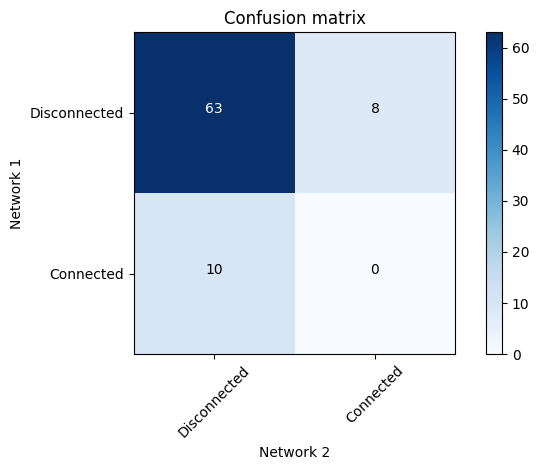

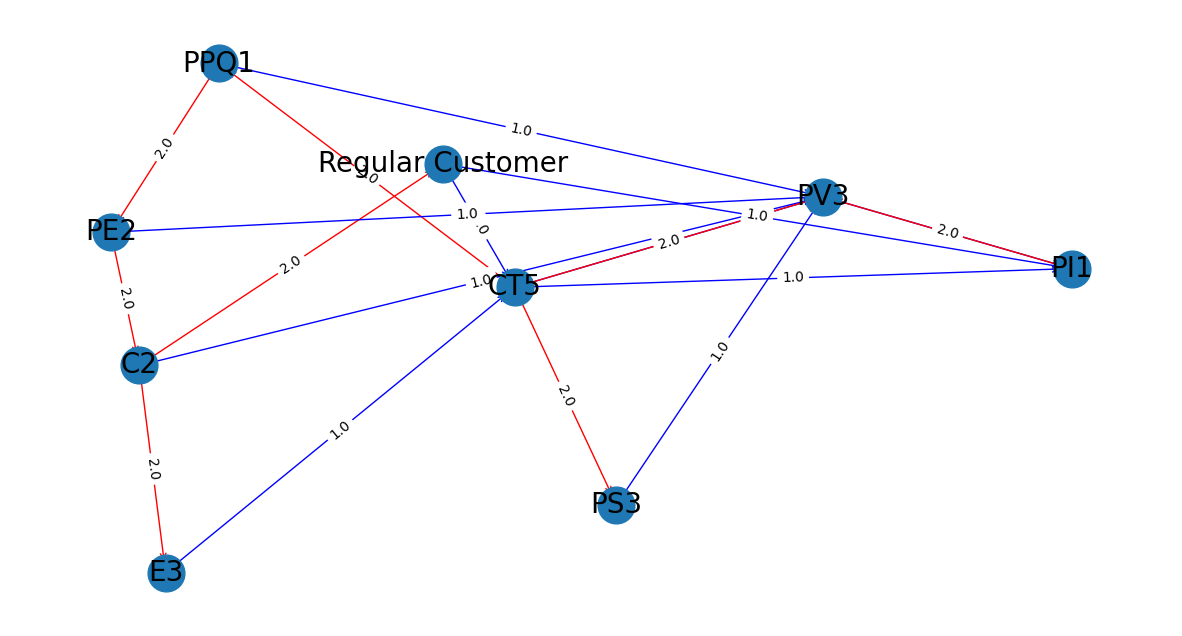

Comparison Results: (array([[63,  8],
       [10,  0]]), target            Regular Customer  CT5  E3  C2  PV3  PE2  PPQ1  PS3  PI1
source                                                                   
Regular Customer                 0   -1   0   0    0    0     0    0   -1
CT5                              0    0   0   0   -1    0     2    2   -1
E3                               0   -1   0   0    0    0     0    0    0
C2                               2    0   2   0   -1    0     0    0    0
PV3                              0    2   0   0    0    0     0    0   -1
PE2                              0    0   0   2   -1    0     0    0    0
PPQ1                             0    0   0   0   -1    2     0    0    0
PS3                              0    0   0   0   -1    0     0    0    0
PI1                              0    0   0   0    2    0     0    0    0)


In [ ]:
#Question 2.3: Comparison of DAGs

comparison = bn.compare_networks(DAG_expert, model_learned)
print("Comparison Results:", comparison)

#Comparison
The expert DAG and the DAG learned from the data generally agree on some of the strongest relationships. For example, relationships such as PV3 → PI1 are likely to appear in both models because this is the strongest statistical relationship in the dataset. However, the two DAGs may differ when it comes to weaker relationships that are mainly based on theory, such as the factors that influence trust.

This difference is expected because BIC-based structure learning relies mainly on statistical relationships and model simplicity within the given sample. In contrast, the expert DAG is based on existing theory and assumptions about how the variables are expected to influence one another. Since the dataset contains only 281 respondents, some theoretical relationships may not be strong enough to be identified through data-driven learning.

1. Pros and Cons of learning a DAG from data

1.1 Pros of learning a DAG from data: Objective and reproducible; not subject to the analyst's personal biases or blind spots; can surface unexpected relationships the analyst wouldn't have hypothesised; scales to problems with many variables where manual theorising is impractical.

1.2. Cons of learning a DAG from data: the learned edges reflect correlation/statistical dependence, not necessarily causal direction; sensitive to sample size, noise, and the specific score/search algorithm used (different scores or search heuristics can yield different DAGs); can produce structures that are statistically optimal but substantively nonsensical or hard to act on.

2. situations would you opt to learn a DAG structure from data:
A data-driven DAG would be appropriate when there is limited existing theory about the relationships between the variables. It can also be useful when there are many variables and it would be difficult to develop the structure manually. Another suitable situation is when the purpose of the analysis is exploratory and aimed at generating new hypotheses rather than testing an established theory. A large and reliable dataset also makes data-driven structure learning more appropriate.

3. When to create a DAG structure as an expert:
An expert DAG is more appropriate when there is strong existing theory or well-established causal knowledge about the relationships between variables. For example, previous consumer-behaviour research may indicate that perceived value mediates the relationship between product quality and purchase intention. Expert knowledge is also useful when the sample size is too small for reliable data-driven learning.

4. Two risks associated with learning a DAG structure from data:

4.1. Unstable edges: With a modest sample (n = 281) and many candidate variables, the search can lock onto correlations that are sampling noise rather than genuine dependence, producing a structure that would look quite different on a fresh sample.

4.2. Wrong causal direction: Another risk is that the data may not provide enough information to determine the true direction of a relationship. Score-based methods can identify a group of DAGs that are statistically equivalent, meaning that different directions can fit the data equally well. For example, the data may support both A to B and B to A. Therefore, treating the direction produced by the algorithm as proof of causation can be misleading.

5. Two risks associated with creating a DAG structure as an expert:

5.1. Confirmation bias: An expert may unintentionally include relationships that support their existing beliefs or the conclusions of the source research, even when the data does not strongly support those relationships. This can lead to confirmation bias, where the analyst focuses more on relationships they already expect to find.

5.2. Missing or omitted relationships: An expert-built DAG is limited by the relationships that the analyst is aware of or considers important. This means that genuine relationships that are unexpected or less obvious may be left out of the network. For example, an unexpected relationship between empathy and price sensitivity may not be included if the analyst did not consider it beforehand.

In [ ]:
#Question 2.4

df_discrete = df_bn.astype(int)

# Learn parameters
model_bn = bn.parameter_learning.fit( DAG_expert,
                                  df_discrete,
                                   methodtype='bayes')

[bnlearn] >Parameter learning> Computing parameters using [bayes]
[bnlearn] >CPD of CT5:
+------------------+-----+---------------------+
| E3               | ... | E3(5)               |
+------------------+-----+---------------------+
| Regular Customer | ... | Regular Customer(2) |
+------------------+-----+---------------------+
| CT5(1)           | ... | 0.1941747572815534  |
+------------------+-----+---------------------+
| CT5(2)           | ... | 0.1941747572815534  |
+------------------+-----+---------------------+
| CT5(3)           | ... | 0.1941747572815534  |
+------------------+-----+---------------------+
| CT5(4)           | ... | 0.1941747572815534  |
+------------------+-----+---------------------+
| CT5(5)           | ... | 0.22330097087378642 |
+------------------+-----+---------------------+
[bnlearn] >CPD of PV3:
+--------+---------+---------+-----+----------------------+
| C2     | C2(1)   | C2(1)   | ... | C2(5)                |
+--------+---------+---------+---

#Question 3

In [ ]:
#Question 3.1
def run_query(evidence, label):
    q = bn.inference.fit(model_bn, variables=['PI1'], evidence=evidence, verbose=0)
    print(f"\n=== {label} ===")
    print(f"Evidence: {evidence}")
    print(q)
    return q

In [ ]:
#Queries
q1 = run_query({'CT5': 5, 'Regular Customer': 1}, 'High trust + Regular customer')
q2 = run_query({'PV3': 5}, 'High perceived value only')
q3 = run_query({'PV3': 1, 'CT5': 1}, 'Low perceived value + Low trust')
q4 = run_query({'PPQ1': 5, 'PS3': 5}, 'High product quality + High price sensitivity')
q5 = run_query({'C2': 5, 'PE2': 5}, 'High convenience + High physical environment rating')
q6 = run_query({'Regular Customer': 2, 'E3': 1}, 'Non-regular customer + Low empathy experience')



=== High trust + Regular customer ===
Evidence: {'CT5': 5, 'Regular Customer': 1}
+--------+------------+
| PI1    |   phi(PI1) |
+========+============+
| PI1(1) |     0.1373 |
+--------+------------+
| PI1(2) |     0.1617 |
+--------+------------+
| PI1(3) |     0.2091 |
+--------+------------+
| PI1(4) |     0.2319 |
+--------+------------+
| PI1(5) |     0.2599 |
+--------+------------+

=== High perceived value only ===
Evidence: {'PV3': 5}
+--------+------------+
| PI1    |   phi(PI1) |
+========+============+
| PI1(1) |     0.1605 |
+--------+------------+
| PI1(2) |     0.1681 |
+--------+------------+
| PI1(3) |     0.1723 |
+--------+------------+
| PI1(4) |     0.2043 |
+--------+------------+
| PI1(5) |     0.2948 |
+--------+------------+

=== Low perceived value + Low trust ===
Evidence: {'PV3': 1, 'CT5': 1}
+--------+------------+
| PI1    |   phi(PI1) |
+========+============+
| PI1(1) |     0.2216 |
+--------+------------+
| PI1(2) |     0.2432 |
+--------+-----------

#Interpretations

##Query 1
This query isolates the combined effect of relational variables — being an already-loyal (Regular Customer = 1) shopper who also reports the highest level of trust (CT5 = 5) in the store. We expect the posterior probability mass for PI1 to shift heavily toward the top categories (4 to 5), since both CT5 and Regular Customer sit directly upstream of PI1 in our expert DAG (one via a direct edge, the other via both a direct edge and an indirect path through PV3). Substantively, this confirms the intuitive retail principle that trust and existing loyalty reinforce each other in driving repurchase intention — for a township-based, subsistence retail environment where relationships with a known trader often substitute for formal loyalty programmes or advertising, this combination is likely to be one of the single strongest predictors of continued patronage available in the dataset.

#Query 2
Here we test the mediating variable in isolation, with no evidence on trust, quality, price or convenience. Because PV3 is the direct parent of PI1 carrying the accumulated influence of C2, PE2, PPQ1, PS3 and CT5, we expect a strong upward shift in PI1's posterior even without directly conditioning on any of its own upstream drivers. This is the clearest test of the paper's central claim — that perceived value mediates purchase intention — implemented structurally in the BN: if the shift in PI1 from this single piece of evidence is comparably large to Query 1's two-variable evidence set, it supports treating value as the key "summary" variable that retailers should track and try to influence, rather than trying to separately manage quality, price, convenience and environment.

#Query 3
This is the pessimistic counterpart to Queries 1 to 2 — a customer who feels they are getting poor value and does not trust the retailer. We expect the posterior for PI1 to concentrate heavily on the lowest categories (1 to 2). The size of this shift, compared to the baseline (unconditional) distribution of PI1, quantifies the "downside risk" retailers face when trust and value both collapse simultaneously — for subsistence retailers with thin margins and repeat-purchase-dependent business models, this combination represents the clearest early-warning signal of customer churn available among our nine variables.

#Query 4
This combination represents a customer who rates product quality highly but is also highly price sensitive — a very plausible profile in a bottom-of-the-pyramid market. Because both variables feed into PV3 (rather than PI1 directly), this query tests whether high price sensitivity *dampens* the positive pull of high perceived quality once it passes through the value node. If the resulting PI1 posterior is noticeably weaker than Query 2's (PV3 = 5 directly), it would suggest that price sensitivity is acting as a partial "brake" on the quality → value → intention pathway — i.e., good products alone are not sufficient to guarantee purchase intention if affordability concerns remain high, reinforcing the source paper's observation that this consumer segment is strongly price sensitive.

#Query 5
This isolates the two more "operational"/store-experience variables (ease of access and store ambience), independent of price, trust or quality evidence. We expect a positive but likely more modest shift in PI1 than Queries 1 to 2, since convenience and environment are further "upstream" (they only influence PI1 indirectly through PV3, and typically explain less variance in purchase intention on their own than trust or value do — recall their bivariate correlations with PI_avg in Section 1.4 were smaller than PV3's or CT5's). Practically, this suggests that while store upgrades (renovation, better location/hours) help, they are unlikely on their own to be as impactful as building trust or perceived value — useful guidance for a resource-constrained township retailer deciding where to invest limited capital.

#Query 6
This profile represents a new/occasional shopper (Regular Customer = 2) who also reports a poor empathy experience from staff. In our expert DAG, E3 only reaches PI1 indirectly, via CT5. We expect this evidence to pull PI1's posterior downward, but by less than the direct, strongly-evidenced Query 3 (low value + low trust), because the influence here is diluted across two indirect steps (E3 to CT5 to PV3/PI1) rather than direct conditioning. Substantively, this query speaks to *customer acquisition* rather than retention: it suggests that a first/occasional shopper's early experience of staff empathy has a real, but comparatively modest, effect on whether they form purchase intentions — useful for thinking about staff-training priorities aimed at converting occasional shoppers into regulars.